# Predicting whether a tumour is malignant or benign

For this assignment I'm using the **Cancer Wisconsin (Diagnostic)** dataset from Kaggle. Each row is one tumour. The features are measurements of the cell nuclei (size, texture, shape and so on) taken from a digitised image, and the label says whether the tumour turned out to be malignant (M) or benign (B).

I'll train two models, **Logistic Regression** and **Random Forest**, and compare them. The maths behind both is explained in the README.

## 1. Loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# In Colab, upload cancer.csv from the Files panel on the left before running this
df = pd.read_csv("cancer.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (569, 32)


         id diagnosis  ...  symmetry_worst  fractal_dimension_worst
0    842302         M  ...          0.4601                  0.11890
1    842517         M  ...          0.2750                  0.08902
2  84300903         M  ...          0.3613                  0.08758
3  84348301         M  ...          0.6638                  0.17300
4  84358402         M  ...          0.2364                  0.07678

[5 rows x 32 columns]

## 2. Cleaning the data

In [2]:
# First check: any missing values or repeated rows?
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# 'id' is only a row label, so it can't help predict anything. Dropping it.
df = df.drop(columns=["id"])

# Some copies of this dataset come with an empty extra column at the end, so I drop it if it exists
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Models need numbers, not letters, so malignant = 1 and benign = 0
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("\nBenign (0) vs malignant (1):")
print(df["diagnosis"].value_counts())

Missing values: 0
Duplicate rows: 0

Benign (0) vs malignant (1):
diagnosis
0    357
1    212
Name: count, dtype: int64


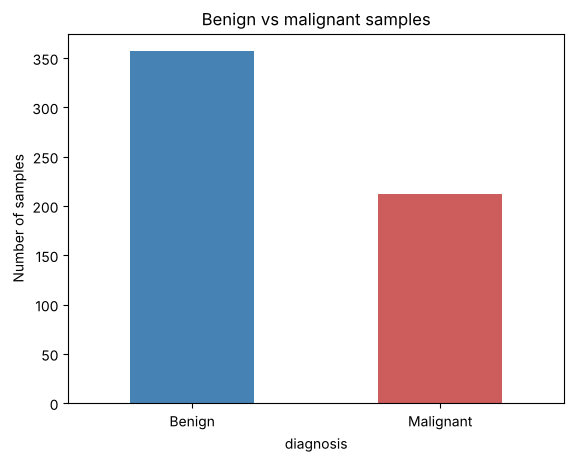

In [3]:
# Quick look at how balanced the two classes are
counts = df["diagnosis"].value_counts().rename({0: "Benign", 1: "Malignant"})
counts.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Benign vs malignant samples")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

## 3. Train / test split

In [4]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# 80% to train on, 20% held back for testing.
# stratify=y keeps the benign/malignant mix the same in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling for logistic regression: the features are on very different scales
# (area is in the hundreds, smoothness is around 0.1). I fit the scaler on the
# training data only, so nothing from the test set leaks in.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 455
Test samples: 114


## 4. Model 1: Logistic Regression

In [5]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

lr_pred = log_reg.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_pred)
print(f"Logistic Regression accuracy: {lr_acc:.4f}\n")
print(classification_report(y_test, lr_pred, target_names=["Benign", "Malignant"]))

Logistic Regression accuracy: 0.9649

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 5. Model 2: Random Forest

In [6]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)   # trees only compare values to thresholds, so no scaling needed

rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest accuracy: {rf_acc:.4f}\n")
print(classification_report(y_test, rf_pred, target_names=["Benign", "Malignant"]))

Random Forest accuracy: 0.9649

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## 6. Comparing the two models

Logistic Regression accuracy: 0.9649
Random Forest accuracy:       0.9649


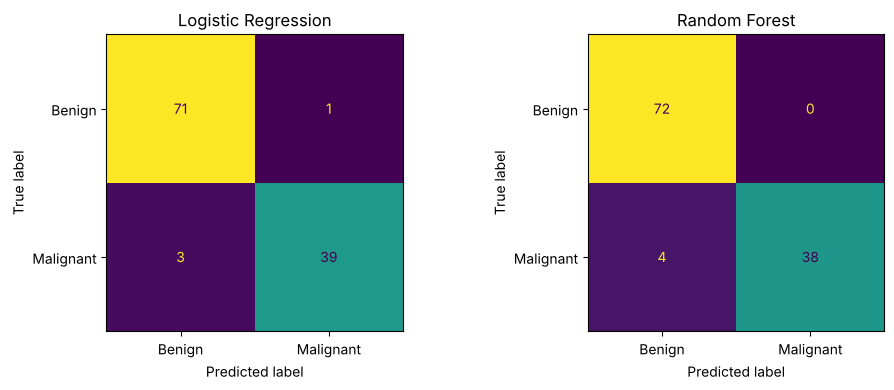

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, name in zip(axes, [lr_pred, rf_pred], ["Logistic Regression", "Random Forest"]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

print(f"Logistic Regression accuracy: {lr_acc:.4f}")
print(f"Random Forest accuracy:       {rf_acc:.4f}")

### Is one lucky split hiding something? Cross-validation

In [8]:
# The test set only has 114 rows, so one or two cases can swing the score.
# 5-fold cross-validation trains and tests on five different splits of the whole dataset.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_cv = cross_val_score(lr_pipe, X, y, cv=skf)
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=skf)

print("Logistic Regression fold scores:", lr_cv.round(4))
print(f"  mean = {lr_cv.mean():.4f}, std = {lr_cv.std():.4f}")
print("Random Forest fold scores:      ", rf_cv.round(4))
print(f"  mean = {rf_cv.mean():.4f}, std = {rf_cv.std():.4f}")

Logistic Regression fold scores: [0.9737 0.9474 0.9649 0.9912 0.9912]
  mean = 0.9737, std = 0.0166
Random Forest fold scores:       [0.9649 0.9386 0.9561 0.9474 0.9646]
  mean = 0.9543, std = 0.0102


## 7. Which features mattered?

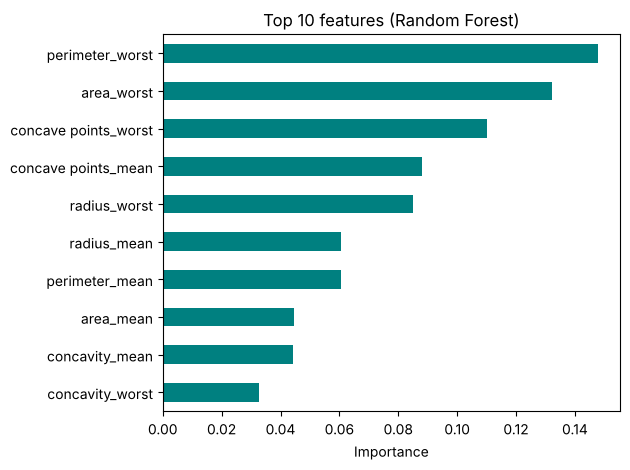

perimeter_worst         0.147912
area_worst              0.132269
concave points_worst    0.110114
concave points_mean     0.088200
radius_worst            0.085116
radius_mean             0.060554
perimeter_mean          0.060465
area_mean               0.044701
concavity_mean          0.044091
concavity_worst         0.032828
dtype: float64

In [9]:
# Random Forest: how much each feature reduced impurity across all the trees
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances

In [10]:
# Logistic Regression: the coefficients (on scaled features) show direction and strength
coefs = pd.Series(log_reg.coef_[0], index=X.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

texture_worst          1.434093
radius_se              1.233325
symmetry_worst         1.061264
concave points_mean    0.952813
concavity_worst        0.911406
area_se                0.909029
compactness_se        -0.906925
area_worst             0.900477
radius_worst           0.896968
concavity_mean         0.782298
dtype: float64